
# Stokes problem with fieldsplit preconditioner (PETSc)
.. index::
   triple: Equations; Stokes; Saddle-Point;

.. index:: Methods; Mixed FEM

.. index:: Spaces; Taylor-Hood

.. index:: Solvers; Petsc fieldsplit

Using Bercovier-Engelmann Testcase
Reference case with analytical solution from:
https://numtourcfd.pages.math.cnrs.fr/doc/NumtourCFD/v1.0.1-alpha.2/applications/validation/bercovier-engelman.html
Original Work: https://doi.org/10.1016/0021-9991(79)90098-6
Equations for $f$ from the benchmark document with DOI: 10.1007/978-3-319-57397-7_12

In [1]:
from matplotlib import pyplot
import numpy as np
try:
    import sys, petsc4py
    petsc4py.init(sys.argv)
    from petsc4py import PETSc
except:
    print("""
Example requires `petsc4py` - not running.
          """)
    import sys
    sys.exit(0)

from dune.grid import structuredGrid
from ufl import div, grad, inner, dx, conditional, as_vector, eq, conditional
from ufl import SpatialCoordinate, TrialFunction, TestFunction
from ufl.constantvalue import Zero
from dune.ufl import DirichletBC, BoundaryId
from dune.fem.function import uflFunction
from dune.fem.space import lagrange, combined
from dune.fem.operator import galerkin,linear
from dune.fem import assemble

We want to use a Taylor-Hood finite-element approximation but solve using
`petsc4py`. To simplify that we use the `petsc` storage when setting up
the velocity and pressure spaces:

In [2]:
velocity_order = 3
gridView = structuredGrid([0, 0], [1, 1], [7, 7])
space_velocity = lagrange(gridView, dimRange=2, order=velocity_order, storage="petsc")
space_pressure = lagrange(gridView, order=velocity_order-1, storage="petsc")
taylor_hood_space = combined(space_velocity, space_pressure, components=["velocity", "pressure"])

The setup of our first test case follows that of [our first Stokes example](monolithicStokes_nb.ipynb)
using the same right hand side and boundary data:

In [3]:
x,y = SpatialCoordinate(taylor_hood_space)

u_exact = uflFunction(gridView, name="analytical_solution_x", order=5,
                      ufl=-256*y*(y-1)*(2*y-1)*x**2*(x-1)**2)
v_exact = uflFunction(gridView, name="analytical_solution_y", order=5,
                      ufl=256*x*(x-1)*(2*x-1)*y**2*(y-1)**2)
p_exact = uflFunction(gridView, name="analytical_solution_pressure", order=5,
                      ufl=(x-0.5)*(y-0.5))
def f_1(x,y):
    return 256*(x**2*(x-1)**2*(12*y-6) + y*(y-1)*(2*y-1)*(12*x**2 -12*x + 2))
f_exact = uflFunction(gridView, name="analytical_solution_force_term", order=5,
                      ufl=as_vector([f_1(x,y) + (y-0.5), -f_1(y,x) +(x-0.5)]) )

In [4]:
U,V      = TrialFunction(taylor_hood_space), TestFunction(taylor_hood_space)
u_h, v_h = as_vector([U[0], U[1]]), as_vector([V[0], V[1]])
p_h, q_h = U[2], V[2]

viscous_stress = inner(grad(u_h), grad(v_h))*dx
pressure_force = -p_h*div(v_h)*dx
continuity = div(u_h)*q_h*dx
eqns = ( viscous_stress + pressure_force + continuity == inner(f_exact,v_h)*dx )

is_left  = eq(BoundaryId(taylor_hood_space),1)
is_right = eq(BoundaryId(taylor_hood_space),2)
is_bot   = eq(BoundaryId(taylor_hood_space),3)
is_top   = eq(BoundaryId(taylor_hood_space),4)
dirichlet_bcs_exact   = [DirichletBC(taylor_hood_space, [u_exact, v_exact, None], is_left),
                         DirichletBC(taylor_hood_space, [u_exact, v_exact, None], is_right),
                         DirichletBC(taylor_hood_space, [u_exact, v_exact, None], is_bot),
                         DirichletBC(taylor_hood_space, [u_exact, v_exact, None], is_top)]
op = galerkin( [eqns, *dirichlet_bcs_exact] )  # we will need the 'operator' again later so we don't use `assemble`
A,b = linear(op, affineShift=True)
b *= -1 # note that the `linear` function returns the affine shift and not the right hand side

We next setup a `fieldsplit` preconditioner using `petsc4py`. The
preconditioner needs the pressure mass matrix in addition to the Stokes
system matrix:

In [5]:
m = inner(grad(u_h), grad(v_h))*dx + p_h*q_h*dx
M = assemble([m,*dirichlet_bcs_exact])

Finally the setup of the petsc structures and the solve step:

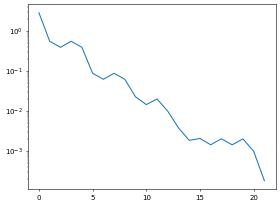

In [6]:
Amat,Mmat,bvec = A.as_petsc, M.as_petsc, b.as_petsc
ksp = PETSc.KSP().create()
ksp.setType(PETSc.KSP.Type.TFQMR)
pc = ksp.getPC()
pc.setType(PETSc.PC.Type.FIELDSPLIT)
idxVelo = PETSc.IS().createStride(size=space_velocity.size, first=0, step=1)
idxPres = PETSc.IS().createStride(size=space_pressure.size, first=space_velocity.size, step=1)
pc.setFieldSplitIS(('velo', idxVelo), ('pres', idxPres))
subksps = pc.getFieldSplitSubKSP()
subksps[0].setType("preonly")
subksps[0].getPC().setType("hypre")
subksps[1].setType("preonly")
subksps[1].getPC().setType("hypre")
ksp.setOperators(Amat, Mmat)
pc.setFieldSplitType(4)           # 0 means additive, 4=Schur
ksp.setFromOptions()
ksp.setConvergenceHistory()
(xvec, _) = Amat.getVecs()
ksp.solve(bvec, xvec)
pyplot.semilogy(ksp.getConvergenceHistory())

The petsc solver returns a petsc vector which we can easily convert into
a discrete function and then visualize:

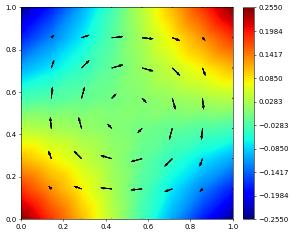

In [7]:
solution_vector_cg = taylor_hood_space.function(name="solution_vector_petsc", dofVector=xvec)
fig = pyplot.figure()
solution_vector_cg.plot(vectors=[0,1], gridLines=None, figure=fig)
solution_vector_cg[2].plot(figure=fig, gridLines=None)

We can easily reuse the same solver to solve a different problem, i.e., a 
standard pipe flow. In this case there is
no forcing and we only need to change the velocity boundary conditions.
We still assume that the velocity is fixed along the whole boundary
and consequently the two matrices constructed previously can be reused.
We only need to set the boundary values in the right hand side vector.
Note that the definition of the `DirichletBc` classes used to
construct the operator already guarantee that only the velocity will be
constraint at the boundary while the pressure is not touched. To set new
boundary values we can use the `setConstraints` method on the
operator but the API requires that we pass in a function into $R^3$,
i.e., including pressure values. This last component of the boundary data
will be ignored.

In [8]:
b.clear()
g = uflFunction(gridView, name="boundaryData", order=2, ufl=as_vector([y*(1-y),0,0]))
op.setConstraints(g,b)
ksp.setOperators(A.as_petsc, M.as_petsc)
ksp.solve(b.as_petsc, xvec)

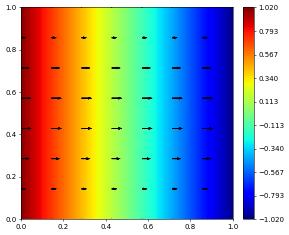

In [9]:
fig = pyplot.figure()
solution_vector_cg.plot(vectors=[0,1], gridLines=None, figure=fig)
solution_vector_cg[2].plot(figure=fig, gridLines=None)
pyplot.show()